In [1]:
import pandas as pd
import numpy as np
import random
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from  lightgbm import LGBMRegressor,LGBMClassifier,log_evaluation,early_stopping

import warnings #avoid some negligible errors

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, make_scorer, precision_recall_curve, auc
from datetime import datetime, timedelta
import random
from sklearn.metrics import average_precision_score,  accuracy_score, precision_score, recall_score, f1_score, \
    precision_recall_curve, auc, roc_curve, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier
import gc
import matplotlib as mpl
import ydata_profiling
from ydata_profiling import ProfileReport
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedKFold, train_test_split
# from pandas_profiling import ProfileReport
import plotly.figure_factory as ff
# from phik import resources
from phik.binning import bin_data
from phik.report import plot_correlation_matrix
from plotnine import *
from plotnine.data import *
import patchworklib as pw

from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

#The filterwarnings () method is used to set warning filters, which can control the output method and level of warning information.
warnings.filterwarnings('ignore')

# Configuration
warnings.filterwarnings('ignore')

SEED = 77

# --- 1. Set Seed ---
def seed_everything(seed):
    np.random.seed(seed)
    random.seed(seed)
    
seed_everything(seed=SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 150)
pd.options.display.float_format = "{:,.2f}".format

def to_decimal(valor, casas_dec = 0, as_percent = False, matplotTextAxe=None):
    """
    valor: Vaor recebido que pode ser uma string um inteiro ou um Objeto matplotlib
    casas_dec: Números de Casas Decimais
    as_percent: True ou Flase, default False para mostrar como percentual.
    matplotTextAxe: Aceita os valores de 'x' ou 'y' indicando qual eixo ticklabels
    return: Retorna o valor formatado conforme os argumentos passados.
    """
    eixo = 0
    if matplotTextAxe != None:
        if matplotTextAxe not in ('x','y'): raise ValueError("Erro! matplotTextAxe")
        elif matplotTextAxe == 'x': eixo = 0
        else: eixo = 1
    v = ''
    if as_percent: v = '%'
    if isinstance(valor, mpl.text.Text): valor = valor.get_position()[eixo]
    if casas_dec == 0: return ("{:,.0f}".format(float(valor))) + v
    else: return ("{:,.2f}".format(float(valor))) + v
    
def limpa_memoria(variaveis: list=[]):
    #torch.cuda.empty_cache()
    plt.clf()# Limpa a figura atual
    plt.cla()# Limpa o gráfico atual
    plt.close('all')
    for i in variaveis:
        del i
    x = 1
    while x > 0:
        x = gc.collect()
    pass

def plota_confusion_matrix(y_true, y_pred):
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        # normalize='true', None
        cmap='Blues', 
        ax=ax1
    )
    ax1.set_title("Matriz Absoluta")

    disp2 = ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        normalize='true',
        values_format='.0%',
        cmap='Blues',
        ax=ax2
    )

    ax2.set_title('Matriz Normalizada (%)')
    
    plt.show()
    limpa_memoria();

def tune_model(modelo, param_grid, X, y, n_iter=50, scoring='average_precision', random_state=SEED, n_jobs=6):
    from sklearn.model_selection import StratifiedKFold
    
    nm_modelo = modelo.__class__.__name__
    print(f"Tuning do modelo: {nm_modelo}")

    #Validação Cruzada
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)   #KFold(n_splits=n_iter, shuffle=True, random_state=random_state)

    #RandomizedSearchCV para busca mais rápida
    grid_search = RandomizedSearchCV( 
    estimator=modelo, 
    param_distributions=param_grid,
    n_iter=n_iter,
    cv=skf,
    scoring=scoring,
    n_jobs=n_jobs,
    random_state=random_state, 
    verbose=1
    )

    grid_search.fit(X,y)
    print(f"Melhores Hiperparâmetros para {nm_modelo}:{grid_search.best_params_}")
    limpa_memoria()
    #Retorna o modelo treinado com os melhores hiperparâmetros
    return grid_search.best_estimator_

def plot_missing_bar(df: pd.DataFrame, top=30, figsize=(9, 7)):
    miss = (df.isna().mean()*100).sort_values(ascending=False).head(top)
    plt.figure(figsize=figsize)
    plt.barh(miss.index[::-1], miss.values[::-1])
    plt.xlabel("% de ausentes")
    plt.title(f"Top {top} variáveis com maior proporção de valores ausentes")
    plt.tight_layout()
    plt.show()

def plota_classificarion_report(ytest, ypred):

    # y_test, y_pred
    rep = classification_report(ytest, ypred, output_dict=True, zero_division=0)
    df_rep = pd.DataFrame(rep).T

    # ordenar e formatar
    cols_order = ["precision", "recall", "f1-score", "support"]
    df_rep = df_rep[cols_order]
    df_rep[["precision", "recall", "f1-score"]] = df_rep[["precision", "recall", "f1-score"]].round(2)


    # usa df_rep do bloco anterior
    plt.figure(figsize=(6, 3.2))
    sns.heatmap(
        df_rep[["precision","recall","f1-score"]],
        annot=True, fmt=".3f",
        linewidths=0.5, linecolor="white",
        cbar=True
    )
    plt.title("Classification Report (Precision / Recall / F1)")
    plt.ylabel("Classe")
    plt.xlabel("Métrica")
    plt.tight_layout()
    plt.show()
    plt.close();

def garantee_dtime(column:pd.Series) -> pd.Series:
    column = pd.to_datetime(column, errors='coerce')
    return column

def plota_proporcao(df: pd.DataFrame, column: str, titulo: str = "Quantitativo dos valores"):

    values = ( df[column].value_counts(dropna=False) / df[column].shape[0] ) * 100
    values = pd.DataFrame(values).reset_index()

    plt.figure(figsize=(6, 5))
    ax = sns.barplot(x=values[column], y=values['count'], palette='coolwarm', hue=values[column].map({0: 'Negativo', 1: 'Positivo'}))
    plt.title(label=titulo)
    plt.xlabel(f'Valores para {column}')
    plt.ylabel('Proporção dos registros')

    plt.ylim(0, 110) 

    #Rótulo das barras
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f"{h:.2f}%", 
                    (p.get_x() + p.get_width()/2, h),
                    ha='center',
                    va='bottom',
                    xytext=(0,5), 
                    textcoords="offset points"
                    )
    plt.show()
    limpa_memoria();

def val_cross(models, param_spaces, n_iter, X, y, x_teste=None, y_teste=None, njobs=6):

    from datetime import datetime as dtm
    from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    print('Início do modelo...')
    print(f'Hora Início...: {dtm.now().hour}:{dtm.now().minute}h')

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    print(f'Feitas validações cruzadas. N-Iter = {n_iter}')
    print(f'Métrica de avaliação - PR-AUC')

    scorer = 'average_precision'
    # scorer = 'balanced_accuracy' #TODO:

    results = {}
    best_models = {}
    best_params = {}
    mean_scores = {}
    best_thresholds = {}

    # 🔵 Controle do melhor modelo global
    best_global_score = -np.inf
    best_global_name = None
    best_global_model = None

    for nome, model in models.items():

        print(f'\n🔍 Otimizando modelo: {nome}...')
        print(f'Hora Início..{nome}.: {dtm.now().hour}:{dtm.now().minute}h')

        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_spaces[nome],
            n_iter=n_iter,
            cv=cv,
            scoring=scorer,
            n_jobs=njobs,
            random_state=SEED,
            # verbose=0,
            return_train_score=False
        )

        search.fit(X, y)
        print(f'Hora FIM..{nome}.: {dtm.now().hour}:{dtm.now().minute}h')
        
        best_models[nome] = search.best_estimator_
        # 🔵 Calcular threshold ótimo no conjunto de teste (F1 máximo)
        if x_teste is not None and y_teste is not None:

            from sklearn.metrics import precision_recall_curve

            y_prob_test = search.best_estimator_.predict_proba(x_teste)[:, 1]
            precision_t, recall_t, thresholds_t = precision_recall_curve(y_teste, y_prob_test)

            f1_scores = 2 * (precision_t[:-1] * recall_t[:-1]) / (precision_t[:-1] + recall_t[:-1] + 1e-10)

            best_idx = np.argmax(f1_scores)
            best_threshold = thresholds_t[best_idx]

            # salvar threshold
            if 'best_thresholds' not in locals():
                best_thresholds = {}

            best_thresholds[nome] = best_threshold
        best_params[nome] = search.best_params_

        best_index = search.best_index_

        fold_scores = [
            search.cv_results_[f'split{i}_test_score'][best_index]
            for i in range(cv.get_n_splits())
        ]

        results[nome] = fold_scores
        mean_scores[nome] = np.mean(fold_scores)

        print(f"✅ Melhor PR-AUC (CV): {search.best_score_:.4f}")
        print(f"📌 Melhores parâmetros: {search.best_params_}")

        # 🔥 Verifica se é o melhor global
        if search.best_score_ > best_global_score:
            best_global_score = search.best_score_
            best_global_name = nome
            best_global_model = search.best_estimator_
            best_global_estimator = search.best_estimator_

    results_df = pd.DataFrame(results)
    

    print("\n🏆 MELHOR MODELO GLOBAL:")
    print(f"Modelo: {best_global_name}")
    print(f"PR-AUC médio (CV): {best_global_score:.4f}")

    # 🔥 Se existir conjunto de teste → avaliar
    if x_teste is not None and y_teste is not None:

        y_prob = best_global_model.predict_proba(x_teste)[:, 1]
        from sklearn.metrics import average_precision_score

        test_ap = average_precision_score(y_teste, y_prob)

        print(f"PR-AUC no conjunto de teste: {test_ap:.4f}")

    return (
        results_df,
        best_models,
        best_params,
        best_thresholds,   # ← novo
        best_global_name,
        best_global_model,
        best_global_score,
        best_global_estimator
    )

def plota_resultados_boxplot(results_df, y_train, figsize=(8,5), dpis=150):
    # =============================
    # 📊 BOXPLOT
    # =============================

    plt.figure(figsize=figsize, dpi=dpis)
    ax = results_df.boxplot()

    baseline = y_train.mean()

    plt.axhline(
        baseline,
        linestyle='--',
        linewidth=1.5,
        label=f'Baseline (Prevalência) = {baseline:.3f}',
        color='red'
    )

    medians = results_df.median()

    for i, median in enumerate(medians):
        plt.text(
            i + 1,
            median + 0.01,
            f'{median:.3f}',
            horizontalalignment='center',
            fontsize=10,
            fontweight='bold'
        )


    # =============================
    # 🔎 OUTLIERS + MÁXIMO (Q4)
    # =============================

    for i, col in enumerate(results_df.columns):
        values = results_df[col].dropna().values
        
        q1 = np.percentile(values, 25)
        q3 = np.percentile(values, 75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        max_value = values.max()
        outliers = values[values > upper_bound]

        # 🔺 Se houver outlier → marcar o maior outlier
        if len(outliers) > 0:
            max_outlier = outliers.max()
            
            plt.annotate(
                f'Out: {max_outlier:.3f}',
                xy=(i + 1, max_outlier),
                # xytext=(i + 1.15, max_outlier + 0.05),
                xytext=(i + 1, max_outlier + 0.015),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='right'
            )

            # 📈 Também marcar o máximo não-outlier (whisker superior)
            whisker_max = values[values <= upper_bound].max()

            plt.annotate(
                f'Max: {whisker_max:.3f}',
                xy=(i + 1, whisker_max),
                # xytext=(i - 0.25, whisker_max + 0.03),
                xytext=(i + 1, whisker_max + 0.015),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='right'
            )

        # 📈 Se não houver outlier → marcar apenas o máximo
        else:
            plt.annotate(
                f'Max: {max_value:.3f}',
                xy=(i + 1, max_value),
                xytext=(i + 1.15, max_value + 0.05),
                arrowprops=dict(arrowstyle='->', linewidth=1),
                fontsize=9,
                ha='left'
            )

    plt.title("Validação Cruzada (5-fold) - PR-AUC para Predição de Sepse")
    plt.ylabel("PR-AUC")
    plt.xticks(rotation=15)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.ylim((0.0, 1.0))
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

    limpa_memoria()

from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef


def plota_calculate_metrics(y_true, y_pred, y_pred_proba):
    """Calculate comprehensive set of metrics for imbalanced classification."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    bal_accuracy = balanced_accuracy_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    avg_precision = average_precision_score(y_true, y_pred_proba)
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_pred_proba)
    pr_auc = auc(recall_curve, precision_curve)
    
    return {
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'Average_Precision': avg_precision,
        'F1_Score': f1,
        'Balanced_Accuracy': bal_accuracy,
        'MCC': mcc,
        'Specificity': specificity,
        'Sensitivity': sensitivity,
        'Precision': precision,
        'Recall': recall
    }



<Figure size 100x100 with 0 Axes>

# TREINO

In [2]:
# Carrega os dados
df_label = pd.read_csv('Data/training_data/SepsisLabel_train.csv').drop_duplicates()
df_labs = pd.read_csv('Data/training_data/measurement_lab_train.csv').drop_duplicates()
df_measure_meds = pd.read_csv('Data/training_data/measurement_meds_train.csv').drop_duplicates()
df_measure_obs = pd.read_csv('Data/training_data/measurement_observation_train.csv').drop_duplicates()
df_demographics = pd.read_csv('Data/training_data/person_demographics_episode_train.csv').drop_duplicates()
df_drugs = pd.read_csv('Data/training_data/drugsexposure_train.csv').drop_duplicates()

# Padroniza os datatypes das datas para Datetime
df_label['measurement_datetime'] = garantee_dtime(df_label['measurement_datetime'])
df_labs['measurement_datetime'] = garantee_dtime(df_labs['measurement_datetime'])
df_measure_meds['measurement_datetime'] = garantee_dtime(df_measure_meds['measurement_datetime'])
df_measure_obs['measurement_datetime'] = garantee_dtime(df_measure_obs['measurement_datetime'])
df_demographics['visit_start_date'] = garantee_dtime(df_demographics['visit_start_date'])
df_drugs['drug_datetime_hourly'] = garantee_dtime(df_drugs['drug_datetime_hourly']) # drug_datetime_hourly

# Altera todas as colunas de datas para o mesmo nome "datetime"
df_label.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_labs.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_meds.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_obs.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_demographics.rename(columns={'visit_start_date': 'datetime'}, inplace=True)
df_drugs.rename(columns={'drug_datetime_hourly': 'datetime'}, inplace=True)

# TESTE

In [3]:
# Carrega os dados
df_label_test = pd.read_csv('Data/testing_data/SepsisLabel_test.csv').drop_duplicates()
df_labs_test = pd.read_csv('Data/testing_data/measurement_lab_test.csv').drop_duplicates()
df_measure_meds_test = pd.read_csv('Data/testing_data/measurement_meds_test.csv').drop_duplicates()
df_measure_obs_test = pd.read_csv('Data/testing_data/measurement_observation_test.csv').drop_duplicates()
df_demographics_test = pd.read_csv('Data/testing_data/person_demographics_episode_test.csv').drop_duplicates()
df_drugs_test = pd.read_csv('Data/testing_data/drugsexposure_test.csv').drop_duplicates()

# Padroniza os datatypes das datas para Datetime
df_label_test['measurement_datetime'] = garantee_dtime(df_label_test['measurement_datetime'])
df_labs_test['measurement_datetime'] = garantee_dtime(df_labs_test['measurement_datetime'])
df_measure_meds_test['measurement_datetime'] = garantee_dtime(df_measure_meds_test['measurement_datetime'])
df_measure_obs_test['measurement_datetime'] = garantee_dtime(df_measure_obs_test['measurement_datetime'])
df_demographics_test['visit_start_date'] = garantee_dtime(df_demographics_test['visit_start_date'])
df_drugs_test['drug_datetime_hourly'] = garantee_dtime(df_drugs_test['drug_datetime_hourly']) # drug_datetime_hourly

# Altera todas as colunas de datas para o mesmo nome "datetime"
df_label_test.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_labs_test.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_meds_test.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_measure_obs_test.rename(columns={'measurement_datetime': 'datetime'}, inplace=True)
df_demographics_test.rename(columns={'visit_start_date': 'datetime'}, inplace=True)
df_drugs_test.rename(columns={'drug_datetime_hourly': 'datetime'}, inplace=True)

In [4]:
# from tqdm.auto import tqdm
# tqdm.pandas()
# df_labelbkp = df_label.copy() #.progress_apply(lambda x: x[:10] if pd.notna(x) else None)

# TREINO

In [5]:
# TRATA AS COLUNAS
df_measure_meds.rename(columns={	
                                'Systolic blood pressure': 'systolic_pressure',
                                'Diastolic blood pressure': 'diastolic_pressure',
                                'Body temperature': 'temperature',
                                'Respiratory rate': 'resp_rate',
                                'Heart rate': 'heart_rate',
                                'Measurement of oxygen saturation at periphery': 'oxygen_periphery', 
                                'Oxygen/Gas total [Pure volume fraction] Inhaled gas': 'oxygen_total'}, inplace=True)

df_measure_obs = df_measure_obs[['person_id', 
                                'visit_occurrence_id', 
                                'datetime',
                                'Left pupil Diameter Auto', 
                                'Right pupil Diameter Auto', 
                                'Glasgow coma scale',
                                'Capillary refill [Time]', 
                                'Pulse',
                                'Arterial pulse pressure']]

df_measure_obs.rename(columns={
                         
                            'Left pupil Diameter Auto': 'l_pupil_diameter', 
                            'Right pupil Diameter Auto': 'r_pupil_diameter', 
                            'Glasgow coma scale': 'glasgow',
                            'Capillary refill [Time]': 'capillary_refil', 
                            'Pulse': 'pulse',
                            'Arterial pulse pressure': 'art_pressure'
                            }, inplace=True)



#LABS Data
rename_cols = {
    'Bilirubin.total [Moles/volume] in Serum or Plasma': 'bilirubin',
    'C reactive protein [Mass/volume] in Serum or Plasma': 'c_reactive_protein',
    'Procalcitonin [Mass/volume] in Serum or Plasma': 'procalcitonin',
    'Lactate [Moles/volume] in Blood': 'lactate',
    'Creatinine [Mass/volume] in Blood': 'creatinine',
    'Partial thromboplastin time': 'thromboplastin_time', 
    'White blood cell count': 'white_cell', 
    'Hemoglobin [Moles/volume] in Blood': 'hemoglobin', 
    'Base excess in Venous blood by calculation': 'base_excess_venous',
    'Base excess in Arterial blood by calculation': 'base_excess_arterial',
    'Phosphate [Moles/volume] in Serum or Plasma': 'phosphate',
    'Potassium [Moles/volume] in Blood': 'potassium',
    'Neutrophil Ab [Units/volume] in Serum': 'neutrophil_ap',
    'Bicarbonate [Moles/volume] in Arterial blood': 'bicarbonate_arterial',
    'Hematocrit [Volume Fraction] of Blood': 'hematocrit',
    'Glucose [Moles/volume] in Serum or Plasma': 'glucose',
    'Calcium [Moles/volume] in Serum or Plasma': 'calcium',
    'Chloride [Moles/volume] in Blood': 'chloride',
    'Sodium [Moles/volume] in Serum or Plasma': 'sodium',
    'Carbon dioxide [Partial pressure] in Venous blood': 'carbon_dioxide_venous',
    'Oxygen [Partial pressure] in Venous blood': 'oxygen_venous',
    'Albumin [Mass/volume] in Serum or Plasma': 'albumin_venous',
    'Bicarbonate [Moles/volume] in Venous blood': 'bicarbonate_venous',
    'Oxygen [Partial pressure] in Arterial blood': 'oxygen_arterial',
    'Carbon dioxide [Partial pressure] in Arterial blood': 'carbon_dioxide_arterial',
    'Interleukin 6 [Mass/volume] in Body fluid': 'interleukin6',
    'Magnesium [Moles/volume] in Blood': 'magnesium', 
    'Prothrombin time (PT)': 'prothrombin_time',
    'Fibrinogen measurement': 'fibrinogen', 
    'Bilirubin measurement': 'bilirubin_measurement',
    ' activated': 'activated', 
    'Total white blood count': 'white_blood',
    'Platelet count': 'platelet', 
    'Blood venous pH': 'venous_ph',
    'D-dimer level': 'd_dimer_level', 
    'Blood arterial pH': 'arterial_ph',
    'Ionised calcium measurement': 'ionised_calcium'
}

df_labs.rename(columns=rename_cols, inplace=True)
# df_labs = df_labs[cols_to_use]

# TESTE

In [6]:
# TRATA AS COLUNAS
df_measure_meds_test.rename(columns={	
                                'Systolic blood pressure': 'systolic_pressure',
                                'Diastolic blood pressure': 'diastolic_pressure',
                                'Body temperature': 'temperature',
                                'Respiratory rate': 'resp_rate',
                                'Heart rate': 'heart_rate',
                                'Measurement of oxygen saturation at periphery': 'oxygen_periphery', 
                                'Oxygen/Gas total [Pure volume fraction] Inhaled gas': 'oxygen_total'}, inplace=True)

df_measure_obs_test = df_measure_obs_test[['person_id', 
                                'visit_occurrence_id', 
                                'datetime',
                                'Left pupil Diameter Auto', 
                                'Right pupil Diameter Auto', 
                                'Glasgow coma scale',
                                'Capillary refill [Time]', 
                                'Pulse',
                                'Arterial pulse pressure']]

df_measure_obs_test.rename(columns={
                         
                            'Left pupil Diameter Auto': 'l_pupil_diameter', 
                            'Right pupil Diameter Auto': 'r_pupil_diameter', 
                            'Glasgow coma scale': 'glasgow',
                            'Capillary refill [Time]': 'capillary_refil', 
                            'Pulse': 'pulse',
                            'Arterial pulse pressure': 'art_pressure'
                            }, inplace=True)



#LABS Data
rename_cols = {
    'Bilirubin.total [Moles/volume] in Serum or Plasma': 'bilirubin',
    'C reactive protein [Mass/volume] in Serum or Plasma': 'c_reactive_protein',
    'Procalcitonin [Mass/volume] in Serum or Plasma': 'procalcitonin',
    'Lactate [Moles/volume] in Blood': 'lactate',
    'Creatinine [Mass/volume] in Blood': 'creatinine',
    'Partial thromboplastin time': 'thromboplastin_time', 
    'White blood cell count': 'white_cell', 
    'Hemoglobin [Moles/volume] in Blood': 'hemoglobin', 
    'Base excess in Venous blood by calculation': 'base_excess_venous',
    'Base excess in Arterial blood by calculation': 'base_excess_arterial',
    'Phosphate [Moles/volume] in Serum or Plasma': 'phosphate',
    'Potassium [Moles/volume] in Blood': 'potassium',
    'Neutrophil Ab [Units/volume] in Serum': 'neutrophil_ap',
    'Bicarbonate [Moles/volume] in Arterial blood': 'bicarbonate_arterial',
    'Hematocrit [Volume Fraction] of Blood': 'hematocrit',
    'Glucose [Moles/volume] in Serum or Plasma': 'glucose',
    'Calcium [Moles/volume] in Serum or Plasma': 'calcium',
    'Chloride [Moles/volume] in Blood': 'chloride',
    'Sodium [Moles/volume] in Serum or Plasma': 'sodium',
    'Carbon dioxide [Partial pressure] in Venous blood': 'carbon_dioxide_venous',
    'Oxygen [Partial pressure] in Venous blood': 'oxygen_venous',
    'Albumin [Mass/volume] in Serum or Plasma': 'albumin_venous',
    'Bicarbonate [Moles/volume] in Venous blood': 'bicarbonate_venous',
    'Oxygen [Partial pressure] in Arterial blood': 'oxygen_arterial',
    'Carbon dioxide [Partial pressure] in Arterial blood': 'carbon_dioxide_arterial',
    'Interleukin 6 [Mass/volume] in Body fluid': 'interleukin6',
    'Magnesium [Moles/volume] in Blood': 'magnesium', 
    'Prothrombin time (PT)': 'prothrombin_time',
    'Fibrinogen measurement': 'fibrinogen', 
    'Bilirubin measurement': 'bilirubin_measurement',
    ' activated': 'activated', 
    'Total white blood count': 'white_blood',
    'Platelet count': 'platelet', 
    'Blood venous pH': 'venous_ph',
    'D-dimer level': 'd_dimer_level', 
    'Blood arterial pH': 'arterial_ph',
    'Ionised calcium measurement': 'ionised_calcium'
}

df_labs_test.rename(columns=rename_cols, inplace=True)
# df_labs = df_labs[cols_to_use]

# TREINO

In [7]:
cap_map = {
    'Normal capillary filling': 'normal',
    'Increased capillary filling time': 'increased', 
    'Decreased capillary filling time': 'decreased', 
    np.nan: 'none'
}

df_measure_obs['capillary_refil'] = df_measure_obs['capillary_refil'].map(cap_map)
df_measure_obs = df_measure_obs.rename(columns={'capillary_refil': 'capillary'})

df_measure_obs = (
        pd.concat([df_measure_obs, pd.get_dummies(df_measure_obs, columns=['capillary', 'art_pressure', 'pulse'])
                   .drop(columns=['l_pupil_diameter', 'r_pupil_diameter', 'glasgow', 'person_id', 'visit_occurrence_id', 'datetime'])], axis=1)
        .drop(columns=['capillary', 'pulse', 'art_pressure'])
        )  

df_measure_obs[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']] = df_measure_obs[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']].astype('int32').fillna(0)


# TESTE

In [8]:
cap_map = {
    'Normal capillary filling': 'normal',
    'Increased capillary filling time': 'increased', 
    'Decreased capillary filling time': 'decreased', 
    np.nan: 'none'
}

df_measure_obs_test['capillary_refil'] = df_measure_obs_test['capillary_refil'].map(cap_map)
df_measure_obs_test = df_measure_obs_test.rename(columns={'capillary_refil': 'capillary'})

df_measure_obs_test = (
        pd.concat([df_measure_obs_test, pd.get_dummies(df_measure_obs_test, columns=['capillary', 'art_pressure', 'pulse'])
                   .drop(columns=['l_pupil_diameter', 'r_pupil_diameter', 'glasgow', 'person_id', 'visit_occurrence_id', 'datetime'])], axis=1)
        .drop(columns=['capillary', 'pulse', 'art_pressure'])
        )  

df_measure_obs_test[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']] = df_measure_obs_test[['capillary_decreased',	'capillary_increased',	'capillary_none',
                'capillary_normal',	'art_pressure_Absent',	'art_pressure_Present',
                'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']].astype('int32').fillna(0)


# TREINO

In [9]:
df_label['datetime'] = pd.to_datetime(df_label['datetime'], errors='coerce')
df_label = df_label.dropna(subset=["datetime"])
df_label          = df_label.sort_values(by=['person_id', 'datetime'])
df_labs           = df_labs.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_measure_meds   = df_measure_meds.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_measure_obs    = df_measure_obs.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_demographics   = df_demographics.sort_values(by=['person_id', 'datetime']) #.drop(columns='visit_occurrence_id')


df_demographics = pd.get_dummies(df_demographics, columns=['gender'], dtype=int).rename(columns={'gender_FEMALE': 'female', 'gender_MALE': 'male'})


# FAZ O MERGE ATRIBUINDO O EPISÓDIO MAIS RECENTE AO TIMESTAMP
df_label = df_label.sort_values(["datetime", "person_id"]).reset_index(drop=True)

df_demographics = (
    df_demographics
    .sort_values(["datetime", "person_id"])
    .reset_index(drop=True)
)

df_label = pd.merge_asof(
    df_label,
    df_demographics[
        ["person_id","visit_occurrence_id","datetime","age_in_months","male", "female"]
    ],
    on="datetime",
    by="person_id",
    direction="backward"
)


df_final = (
    # df_label.merge(df_demographics, on=['person_id', 'visit_occurrence_id'], how='left')
    df_label.merge(df_labs, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')
    .merge(df_measure_meds, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')
    .merge(df_measure_obs, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')     
         )

# TESTE

In [10]:
df_label_test['datetime'] = pd.to_datetime(df_label_test['datetime'], errors='coerce')
df_label_test = df_label_test.dropna(subset=["datetime"])
df_label_test          = df_label_test.sort_values(by=['person_id', 'datetime'])
df_labs_test           = df_labs_test.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_measure_meds_test   = df_measure_meds_test.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_measure_obs_test    = df_measure_obs_test.sort_values(by=['person_id', 'datetime', 'visit_occurrence_id']) #.drop(columns='visit_occurrence_id')
df_demographics_test   = df_demographics_test.sort_values(by=['person_id', 'datetime']) #.drop(columns='visit_occurrence_id')


df_demographics_test = pd.get_dummies(df_demographics_test, columns=['gender'], dtype=int).rename(columns={'gender_FEMALE': 'female', 'gender_MALE': 'male'})


# FAZ O MERGE ATRIBUINDO O EPISÓDIO MAIS RECENTE AO TIMESTAMP
df_label_test = df_label_test.sort_values(["datetime", "person_id"]).reset_index(drop=True)

df_demographics_test = (
    df_demographics_test
    .sort_values(["datetime", "person_id"])
    .reset_index(drop=True)
)

df_label_test = pd.merge_asof(
    df_label_test,
    df_demographics_test[
        ["person_id","visit_occurrence_id","datetime","age_in_months","male", "female"]
    ],
    on="datetime",
    by="person_id",
    direction="backward"
)


df_final_test = (
    # df_label_test.merge(df_demographics, on=['person_id', 'visit_occurrence_id'], how='left')
    df_label_test.merge(df_labs_test, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')
    .merge(df_measure_meds_test, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')
    .merge(df_measure_obs_test, on=['person_id', 'datetime', 'visit_occurrence_id'], how='left')     
         )

# EXCLUI PACIENTES COM INTERNACAO MENOR QUE 6h

In [11]:
# episode_sizes = df_final.groupby("visit_occurrence_id").size()

# valid_visits = episode_sizes[episode_sizes >= 6].index

# df_final = df_final[df_final["visit_occurrence_id"].isin(valid_visits)]

In [12]:
last_not_null = lambda x: x.dropna().iloc[-1] if x.notna().any() else np.nan

LIMITS = {
    'temperature': (32.0, 43.0),           # Hipotermia grave → Hiperpirexia letal
    'hematocrit': (12.0, 70.0),            # Anemia extrema → Policitemia neonatal
    'base_excess_venous': (-30.0, 25.0),   # Acidose láctica → Alcalose iatrogênica HCO3
    'base_excess_arterial': (-30.0, 25.0), # ↑
    'phosphate': (0.1, 15.0),              # Hipofosfatemia grave → Rabdomiólise
    'potassium': (1.5, 9.5),               # Hipocalemia letal → Hipercalemia aguda
    'bilirubin': (0.0, 50.0),              # Neonatal grave → Insuficiência hepática
    'neutrophil_ap': (0.0, 80.0),          # Neutropenia → Neutrofilia extrema sepse
    'bicarbonate_arterial': (2.0, 45.0),   # Acidose → Alcalose metabólica grave
    'glucose': (5.0, 800.0),               # Hipoglicemia grave → Hiperglicemia HHS
    'calcium': (4.0, 18.0),                # Hipocalcemia → Hipercalcemia paratireoide
    'chloride': (70.0, 130.0),             # Acidose hiperclorêmica → Alcalose hipoclorêmica
    'sodium': (105.0, 185.0),              # Hiponatremia grave → Hipernatremia letal
    'c_reactive_protein': (0.0, 600.0),    # Normal → Sepse neonatal grave
    'carbon_dioxide_venous': (10.0, 70.0), # Acidose respiratória → Alcalose hipercapnia
    'oxygen_venous': (10.0, 85.0),         # SvO2 choque → Hiperoxia venosa
    'albumin_venous': (0.5, 7.0),          # Hipoalbuminemia grave → Desidratação extrema
    'bicarbonate_venous': (2.0, 45.0),     # ↑
    'oxygen_arterial': (20.0, 650.0),      # Hipoxemia grave → Hiperoxia suplementada
    'carbon_dioxide_arterial': (10.0, 120.0), # Acidose respiratória grave → Hipercapnia
    'interleukin6': (0.0, 50000.0),        # Normal → Sepse grave (pg/mL)
    'magnesium': (0.2, 8.0),               # Hipomagnesemia grave → Hipermagnesemia iatrogênica
    'prothrombin_time': (5.0, 120.0),      # Coagulação hiperativa → CIVD grave
    'procalcitonin': (0.0, 500.0),         # Normal → Sepse fulminante
    'lactate': (0.2, 25.0),                # Normal → Choque lático refratário
    'creatinine': (0.0, 10.0),             # Normal → IRA estágio 3 grave
    'fibrinogen': (20.0, 1200.0),          # Hipofibrinogenemia → Resposta inflamatória aguda
    'bilirubin_measurement': (0.0, 50.0),  # ↑
    'thromboplastin_time': (5.0, 120.0),   # ↑ PT/INR
    'activated': (20.0, 200.0),            # aPTT normal → CIVD grave
    'white_blood': (0.0, 120.0),           # Leucopenia → Leucocitose extrema (10³/µL)
    'platelet': (1.0, 2000.0),             # Trombocitopenia grave → Trombocitose reativa
    'white_cell': (0.0, 120.0),            # ↑
    'venous_ph': (6.5, 7.65),              # Acidose letal → Alcalose extrema
    'd_dimer_level': (0.0, 50.0),          # Normal → CIVD/Tromboembolismo massivo (µg/mL)
    'arterial_ph': (6.5, 7.65),            # ↑
    'hemoglobin': (3.0, 28.0),             # Anemia grave → Policitemia neonatal
    'ionised_calcium': (0.3, 3.5),         # Hipocalcemia grave → Hipercalcemia letal (mmol/L)
    'systolic_pressure': (20.0, 220.0),    # Choque → Crise hipertensiva
    'diastolic_pressure': (10.0, 140.0),   # ↑
    'resp_rate': (0.0, 120.0),             # Apneia → Taquipneia extrema neonatal
    'heart_rate': (20.0, 300.0),           # Bradicardia grave → Taquicardia supraventricular
    'oxygen_periphery': (50.0, 102.0),     # Hipoxemia grave → Hiperoxia suplementada
    'oxygen_total': (50.0, 102.0),         # ↑
    'l_pupil_diameter': (0.5, 10.0),       # Miosis extrema → Midríase total
    'r_pupil_diameter': (0.5, 10.0),       # ↑
    'glasgow': (3.0, 15.0)                 # Coma → Normal
}


def apply_clinical_limits_nan(df, limits):
    df = df.copy()
    for col, (vmin, vmax) in limits.items():
        if col in df.columns:
            df.loc[
                (df[col] < vmin) | (df[col] > vmax),
                col
            ] = np.nan
    return df

df_final = apply_clinical_limits_nan(df_final, limits=LIMITS)


# TESTE

In [13]:
df_final_test = apply_clinical_limits_nan(df_final_test, limits=LIMITS)

# DROPAR !!!!
### Colunas que estão totalmente nulas!

In [14]:
df_final.columns

Index(['person_id', 'datetime', 'SepsisLabel', 'visit_occurrence_id',
       'age_in_months', 'male', 'female', 'base_excess_venous',
       'base_excess_arterial', 'phosphate', 'potassium', 'bilirubin',
       'neutrophil_ap', 'bicarbonate_arterial', 'hematocrit', 'glucose',
       'calcium', 'chloride', 'sodium', 'c_reactive_protein',
       'carbon_dioxide_venous', 'oxygen_venous', 'albumin_venous',
       'bicarbonate_venous', 'oxygen_arterial', 'carbon_dioxide_arterial',
       'interleukin6', 'magnesium', 'prothrombin_time', 'procalcitonin',
       'lactate', 'creatinine', 'fibrinogen', 'bilirubin_measurement',
       'thromboplastin_time', 'activated', 'white_blood', 'platelet',
       'white_cell', 'venous_ph', 'd_dimer_level', 'arterial_ph', 'hemoglobin',
       'ionised_calcium', 'systolic_pressure', 'diastolic_pressure',
       'temperature', 'resp_rate', 'heart_rate', 'oxygen_periphery',
       'oxygen_total', 'l_pupil_diameter', 'r_pupil_diameter', 'glasgow',
       'capil

# TREINO

In [15]:
miss_to_drop = []

notok = ['person_id', 'datetime', 'SepsisLabel', 'hours_before', 'last_datetime', 'first_sepsis_datetime']
encodeds = ['capillary_decreased', 'capillary_increased', 'capillary_none',
       'capillary_normal', 'art_pressure_Absent', 'art_pressure_Present',
       'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak']
ok = [c for c in df_final.columns if c not in notok + encodeds]


c1 = df_final[ok].describe()
# c2 = df[cols].describe()
for i in c1.columns:
    if np.isnan(c1[i]['max']):
        miss_to_drop.append(i)

df_final = df_final.drop(columns=miss_to_drop)
miss_to_drop

['calcium', 'fibrinogen', 'ionised_calcium']

# TESTE

In [16]:
df_final_test = df_final_test.drop(columns=miss_to_drop) # AS MESMAS DO TREINO
miss_to_drop

['calcium', 'fibrinogen', 'ionised_calcium']

1️⃣ Primeiro: ordenar corretamente a série temporal

In [17]:
df_final = df_final.sort_values(by=['person_id', 'datetime']).reset_index(drop=True)

df_final_test = df_final_test.sort_values(by=['person_id', 'datetime']).reset_index(drop=True)

2️⃣ Feature 1 (MIT / Harvard): Shock Index

Muito usada em papers de sepse e choque séptico.  

ShockIndex= SystolicPressure / HeartRate

Valores > 0.9 indicam risco hemodinâmico.

In [18]:
df_final["shock_index"] = (
    df_final["heart_rate"] /
    df_final["systolic_pressure"]
)

df_final_test["shock_index"] = (
    df_final_test["heart_rate"] /
    df_final_test["systolic_pressure"]
)

3️⃣ Feature 2 (MIT / Harvard): MAP (Mean Arterial Pressure)

Fórmula clínica padrão:

𝑀𝐴𝑃=(𝑆𝐵𝑃+2×𝐷𝐵𝑃)/3  

MAP < 65 mmHg é um forte indicador de sepse grave.

In [19]:
df_final["map"] = (
    df_final["systolic_pressure"] +
    2 * df_final["diastolic_pressure"]
) / 3

df_final_test["map"] = (
    df_final_test["systolic_pressure"] +
    2 * df_final_test["diastolic_pressure"]
) / 3

5️⃣ Features temporais fundamentais

Agora vamos criar features que capturam tendência temporal.

Rolling mean (6h)

In [20]:
vitals = [
    "heart_rate",
    "resp_rate",
    "temperature",
    "systolic_pressure",
]

for v in vitals:
    df_final[f"{v}_mean_6h"] = (
        df_final
        .groupby("visit_occurrence_id")[v]
        .rolling(6)
        .mean()
        .reset_index(level=0, drop=True)
    )

for v in vitals:
    df_final_test[f"{v}_mean_6h"] = (
        df_final_test
        .groupby("visit_occurrence_id")[v]
        .rolling(6)
        .mean()
        .reset_index(level=0, drop=True)
    )

Rolling min (6h)

In [21]:
for v in vitals:
    df_final[f"{v}_min_6h"] = (
        df_final
        .groupby("visit_occurrence_id")[v]
        .rolling(6)
        .min()
        .reset_index(level=0, drop=True)
    )

for v in vitals:
    df_final_test[f"{v}_min_6h"] = (
        df_final_test
        .groupby("visit_occurrence_id")[v]
        .rolling(6)
        .min()
        .reset_index(level=0, drop=True)
    )

Variação de 1h  
Isso captura deterioração rápida.

In [22]:
for v in vitals:
    df_final[f"{v}_delta_1h"] = (
        df_final
        .groupby("visit_occurrence_id")[v]
        .diff()
    )

for v in vitals:
    df_final_test[f"{v}_delta_1h"] = (
        df_final_test
        .groupby("visit_occurrence_id")[v]
        .diff()
    )

6️⃣ Outra feature forte: Temperature anomaly

Febre ou hipotermia.

In [23]:
df_final["temp_abnormal"] = (
    (df_final["temperature"] >= 40) |
    (df_final["temperature"] < 35)
).astype(int)

df_final_test["temp_abnormal"] = (
    (df_final_test["temperature"] >= 40) |
    (df_final_test["temperature"] < 35)
).astype(int)

7️⃣ Outra muito usada: Respiratory distress  
Isso vem diretamente dos critérios qSOFA.

In [24]:
df_final["resp_distress"] = (
    df_final["resp_rate"] > 22
).astype(int)

df_final_test["resp_distress"] = (
    df_final_test["resp_rate"] > 22
).astype(int)

8️⃣ Outra muito importante: SOFA cardiovascular proxy

In [25]:
df_final["hypotension"] = (
    df_final["map"] < 65
).astype(int)

df_final_test["hypotension"] = (
    df_final_test["map"] < 65
).astype(int)

9️⃣ Feature de tendência do Glasgow

Queda neurológica é um forte indicador.

In [26]:
df_final["glasgow_delta_3h"] = (
    df_final
    .groupby("visit_occurrence_id")["glasgow"]
    .diff(3)
)

df_final_test["glasgow_delta_3h"] = (
    df_final_test
    .groupby("visit_occurrence_id")["glasgow"]
    .diff(3)
)

🔟 Feature de oxigenação

In [27]:
df_final["oxygen_drop"] = (
    df_final
    .groupby("visit_occurrence_id")["oxygen_periphery"]
    .diff()
)

df_final_test["oxygen_drop"] = (
    df_final_test
    .groupby("visit_occurrence_id")["oxygen_periphery"]
    .diff()
)

6️⃣ Uma melhoria simples que pode subir para 0.83–0.86

Adicionar features de variação temporal.

In [28]:
df_final["hr_delta"] = df_final.groupby(
    "visit_occurrence_id"
)["heart_rate"].diff()

df_final["temp_delta"] = df_final.groupby(
    "visit_occurrence_id"
)["temperature"].diff()

# df_final["wbc_delta"] = df_final.groupby(
#     "visit_occurrence_id"
# )["wbc"].diff()

df_final_test["hr_delta"] = df_final_test.groupby(
    "visit_occurrence_id"
)["heart_rate"].diff()

df_final_test["temp_delta"] = df_final_test.groupby(
    "visit_occurrence_id"
)["temperature"].diff()


Calcular percentual de missing por coluna  
  
0.99 → extremamente conservador  
0.90 → padrão em datasets clínicos

In [29]:
missing_ratio = df_final.isna().mean().sort_values(ascending=False)

threshold = 0.97

cols_to_drop = missing_ratio[missing_ratio >= threshold].index.tolist()

len(cols_to_drop), cols_to_drop

### TEST
# O MESMO DO TREINO

(18,
 ['oxygen_total',
  'albumin_venous',
  'hemoglobin',
  'creatinine',
  'venous_ph',
  'interleukin6',
  'platelet',
  'arterial_ph',
  'activated',
  'oxygen_arterial',
  'bicarbonate_arterial',
  'd_dimer_level',
  'carbon_dioxide_arterial',
  'base_excess_arterial',
  'glasgow_delta_3h',
  'thromboplastin_time',
  'prothrombin_time',
  'white_blood'])

Remover do dataset

In [30]:
df_final = df_final.drop(columns=cols_to_drop)

df_final_test = df_final_test.drop(columns=cols_to_drop) # DEVEM SER AS MESMAS DO TREINO

5️⃣ Proteger colunas essenciais

Sempre garanta que essas colunas nunca sejam removidas:

In [31]:
protected = [
    "person_id",
    "datetime",
    "visit_occurrence_id",
    "SepsisLabel"
]

# cols_to_drop = [
#     c for c in cols_to_drop
#     if c not in protected
# ]

# # df_final = df_final.drop(columns=cols_to_drop)

In [32]:
df_final.shape, df_final_test.shape 

((331624, 64), (130483, 63))

8️⃣ Uma melhoria importante

Como seu dataset é temporal, é melhor calcular missing por paciente também.

Exemplo:

In [33]:
missing_patient = (
    df_final
    .groupby("visit_occurrence_id")
    .apply(lambda x: x.isna().mean())
    .mean()
)
# missing_patient

In [ ]:
df_final.head(3)

# ORDENAR CORRETAMENTE PARA SERIE TEMPORAL

✔️ Correção recomendada

Remover linhas onde nenhuma variável clínica foi medida.

Primeiro definimos colunas clínicas.

In [35]:
clinical_cols = df_final.columns.difference([
    "person_id",
    "datetime",
    "visit_occurrence_id",
    "SepsisLabel"
])

clinical_cols_test = df_final_test.columns.difference([
    "person_id",
    "datetime",
    "visit_occurrence_id",
    "SepsisLabel"
])

df_final = df_final.dropna(
    subset=clinical_cols,
    how="all"
)

df_final_test = df_final_test.dropna(
    subset=clinical_cols_test,
    how="all"
)

In [36]:
df_final = df_final.sort_values(
    ["visit_occurrence_id", "datetime"]
)

df_final_test = df_final_test.sort_values(
    ["visit_occurrence_id", "datetime"]
)

In [37]:
df_final = df_final.drop(columns=["female"]) # Excluir multicolineridade

df_final_test = df_final_test.drop(columns=["female"]) # Excluir multicolineridade

2️⃣ Forward fill dentro de cada paciente

Nunca faça ffill() global.

3️⃣ Limitar propagação (MUITO recomendado)

O ideal é não propagar valores indefinidamente.

Em estudos clínicos costuma-se limitar a 6 ou 12 horas.

In [38]:
cols_to_fill = df_final.columns.difference([
    "person_id",
    "datetime",
    "visit_occurrence_id",
    "SepsisLabel"
])

df_final[cols_to_fill] = (
    df_final
    .groupby("visit_occurrence_id")[cols_to_fill]
    .ffill(limit=12)
)

# TESTE

cols_to_fill_test = df_final_test.columns.difference([
    "person_id",
    "datetime",
    "visit_occurrence_id"
])

df_final_test[cols_to_fill_test] = (
    df_final_test
    .groupby("visit_occurrence_id")[cols_to_fill_test]
    .ffill(limit=12)
)

5️⃣ Depois do ffill ainda existirão NaNs

Normal.

Exames que nunca foram coletados continuarão NaN.

Agora você tem duas opções padrão em papers:

opção A (mais comum)

Preencher com mediana global

In [39]:
(df_final.isna().sum() / df_final.shape[0]) * 100 

person_id                     0.00
datetime                      0.00
SepsisLabel                   0.00
visit_occurrence_id           0.00
age_in_months                 0.00
male                          0.00
base_excess_venous           55.51
phosphate                    84.61
potassium                    44.25
bilirubin                    79.69
neutrophil_ap                56.52
hematocrit                   50.57
glucose                      76.09
chloride                     43.08
sodium                       43.01
c_reactive_protein           56.42
carbon_dioxide_venous        55.98
oxygen_venous                62.28
bicarbonate_venous           51.37
magnesium                    79.22
procalcitonin                65.61
lactate                      51.53
bilirubin_measurement        85.57
white_cell                   51.12
systolic_pressure            75.94
diastolic_pressure           75.96
temperature                  10.62
resp_rate                    74.27
heart_rate          

In [40]:
df_final[cols_to_fill] = df_final[cols_to_fill].fillna(
    df_final[cols_to_fill].median()
)

# TEST
df_final_test[cols_to_fill_test] = df_final_test[cols_to_fill_test].fillna(
    df_final_test[cols_to_fill_test].median()
)

In [41]:
df_final.isna().mean().sort_values(ascending=False).head(10)

person_id             0.00
datetime              0.00
SepsisLabel           0.00
visit_occurrence_id   0.00
age_in_months         0.00
male                  0.00
base_excess_venous    0.00
phosphate             0.00
potassium             0.00
bilirubin             0.00
dtype: float64

In [42]:
# df_final[df_final["age_in_months"] == 0]["person_id"].nunique()
df_final["age_in_months"].describe()

count   331,624.00
mean         53.27
std          66.56
min           0.00
25%           3.00
50%          15.00
75%          93.00
max         256.00
Name: age_in_months, dtype: float64

In [43]:
df_final.columns

Index(['person_id', 'datetime', 'SepsisLabel', 'visit_occurrence_id',
       'age_in_months', 'male', 'base_excess_venous', 'phosphate', 'potassium',
       'bilirubin', 'neutrophil_ap', 'hematocrit', 'glucose', 'chloride',
       'sodium', 'c_reactive_protein', 'carbon_dioxide_venous',
       'oxygen_venous', 'bicarbonate_venous', 'magnesium', 'procalcitonin',
       'lactate', 'bilirubin_measurement', 'white_cell', 'systolic_pressure',
       'diastolic_pressure', 'temperature', 'resp_rate', 'heart_rate',
       'oxygen_periphery', 'l_pupil_diameter', 'r_pupil_diameter', 'glasgow',
       'capillary_decreased', 'capillary_increased', 'capillary_none',
       'capillary_normal', 'art_pressure_Absent', 'art_pressure_Present',
       'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak',
       'shock_index', 'map', 'heart_rate_mean_6h', 'resp_rate_mean_6h',
       'temperature_mean_6h', 'systolic_pressure_mean_6h', 'heart_rate_min_6h',
       'resp_rate_min_6h', 'temperatu

# FEATURES EM SEQUENCIA TEMPORAL

In [44]:
df_final['visit_occurrence_id'].min(), df_final['visit_occurrence_id'].max() 

(np.int64(933758), np.int64(2147326527))

5️⃣ Separar treino e teste corretamente

Nunca dividir por linha.

Divisão deve ser por paciente.

In [47]:
df_final.columns

Index(['person_id', 'datetime', 'SepsisLabel', 'visit_occurrence_id',
       'age_in_months', 'male', 'base_excess_venous', 'phosphate', 'potassium',
       'bilirubin', 'neutrophil_ap', 'hematocrit', 'glucose', 'chloride',
       'sodium', 'c_reactive_protein', 'carbon_dioxide_venous',
       'oxygen_venous', 'bicarbonate_venous', 'magnesium', 'procalcitonin',
       'lactate', 'bilirubin_measurement', 'white_cell', 'systolic_pressure',
       'diastolic_pressure', 'temperature', 'resp_rate', 'heart_rate',
       'oxygen_periphery', 'l_pupil_diameter', 'r_pupil_diameter', 'glasgow',
       'capillary_decreased', 'capillary_increased', 'capillary_none',
       'capillary_normal', 'art_pressure_Absent', 'art_pressure_Present',
       'art_pressure_Weak', 'pulse_Absent', 'pulse_Present', 'pulse_Weak',
       'shock_index', 'map', 'heart_rate_mean_6h', 'resp_rate_mean_6h',
       'temperature_mean_6h', 'systolic_pressure_mean_6h', 'heart_rate_min_6h',
       'resp_rate_min_6h', 'temperatu

In [65]:
X = df_final.drop(columns=['person_id', 'datetime', 'SepsisLabel', 'visit_occurrence_id'])
y = df_final['SepsisLabel']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=77)

X_base_test = df_final_test.drop(columns=['person_id', 'datetime', 'visit_occurrence_id'])


In [55]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape, X_base_test.shape

((232136, 59), (232136,), (99488, 59), (99488,), (130483, 59))

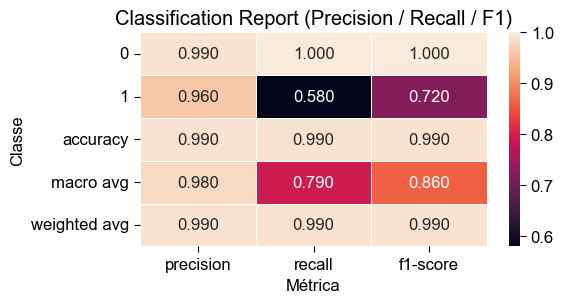

In [59]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=2000,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="aucpr",
    class_weight = {0:1, 1:240}
)

model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:,1]
y_pred = model.predict(X_test)

plota_classificarion_report(y_test, y_pred)



In [78]:
proba_test = model.predict_proba(X_base_test)[:,1]

pred_test = model.predict(X_base_test)

proba_test.shape, pred_test.shape

((130483,), (130483,))

2️⃣ Primeiro: carregar scaler e modelo

Você deveria salvar depois do treino:

In [61]:
X_base_test.shape

(130483, 59)

3️⃣ Preparar a base de teste

Ela não terá SepsisLabel, então:

In [ ]:
# features = df_test.drop(
#     columns=["person_id","datetime"]
# ).columns

NameError: name 'df_test' is not defined

In [ ]:
# probs = model.predict(X_test)

# probs_test = model.predict(X_base_test)

# probs, probs_test

(array([0, 0, 0, ..., 0, 0, 0]), array([0, 0, 0, ..., 0, 0, 0]))

🔟 Gerar saída final

Durante criação das janelas você pode salvar o ID.

Exemplo:

In [82]:
len(proba_test.flatten())

130483

In [ ]:
df_submit = pd.DataFrame({
    "person_id_datetime":
        df_final_test["person_id"].astype(str)
        + "_"
        + df_final_test["datetime"].astype(str),

    "SepsisLabel": proba_test #pred_test
})



In [83]:
proba_test

array([1.6246230e-04, 5.9038834e-05, 7.2113849e-05, ..., 1.7068038e-02,
       1.7068038e-02, 1.7068038e-02], dtype=float32)

In [90]:
(pd.Series(proba_test)>=0.02).value_counts(dropna=False)

False    117729
True      12754
Name: count, dtype: int64

In [81]:
df_submit['SepsisLabel'].value_counts()

SepsisLabel
0    130418
1        65
Name: count, dtype: int64

In [91]:
df_submit["person_id_datetime"] = (
    df_submit["person_id_datetime"]
    .str.replace(".000000000","",regex=False)
)

In [ ]:
df_submit

In [95]:
dfbkp = df_submit.copy()

In [ ]:
df_submit.set_index(keys='person_id_datetime', drop=True, inplace=True)
df_submit.head(3)

In [ ]:
df_submit.to_csv('juscelino_BR_phems_hackathon2.csv')

: 